# Morfologia I: erosão e dilatação

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
import cv2

from src.preprocessamento import para_cinza
from src.segmentacao import segmentar_otsu
from src.morfologia import erosao, dilatacao

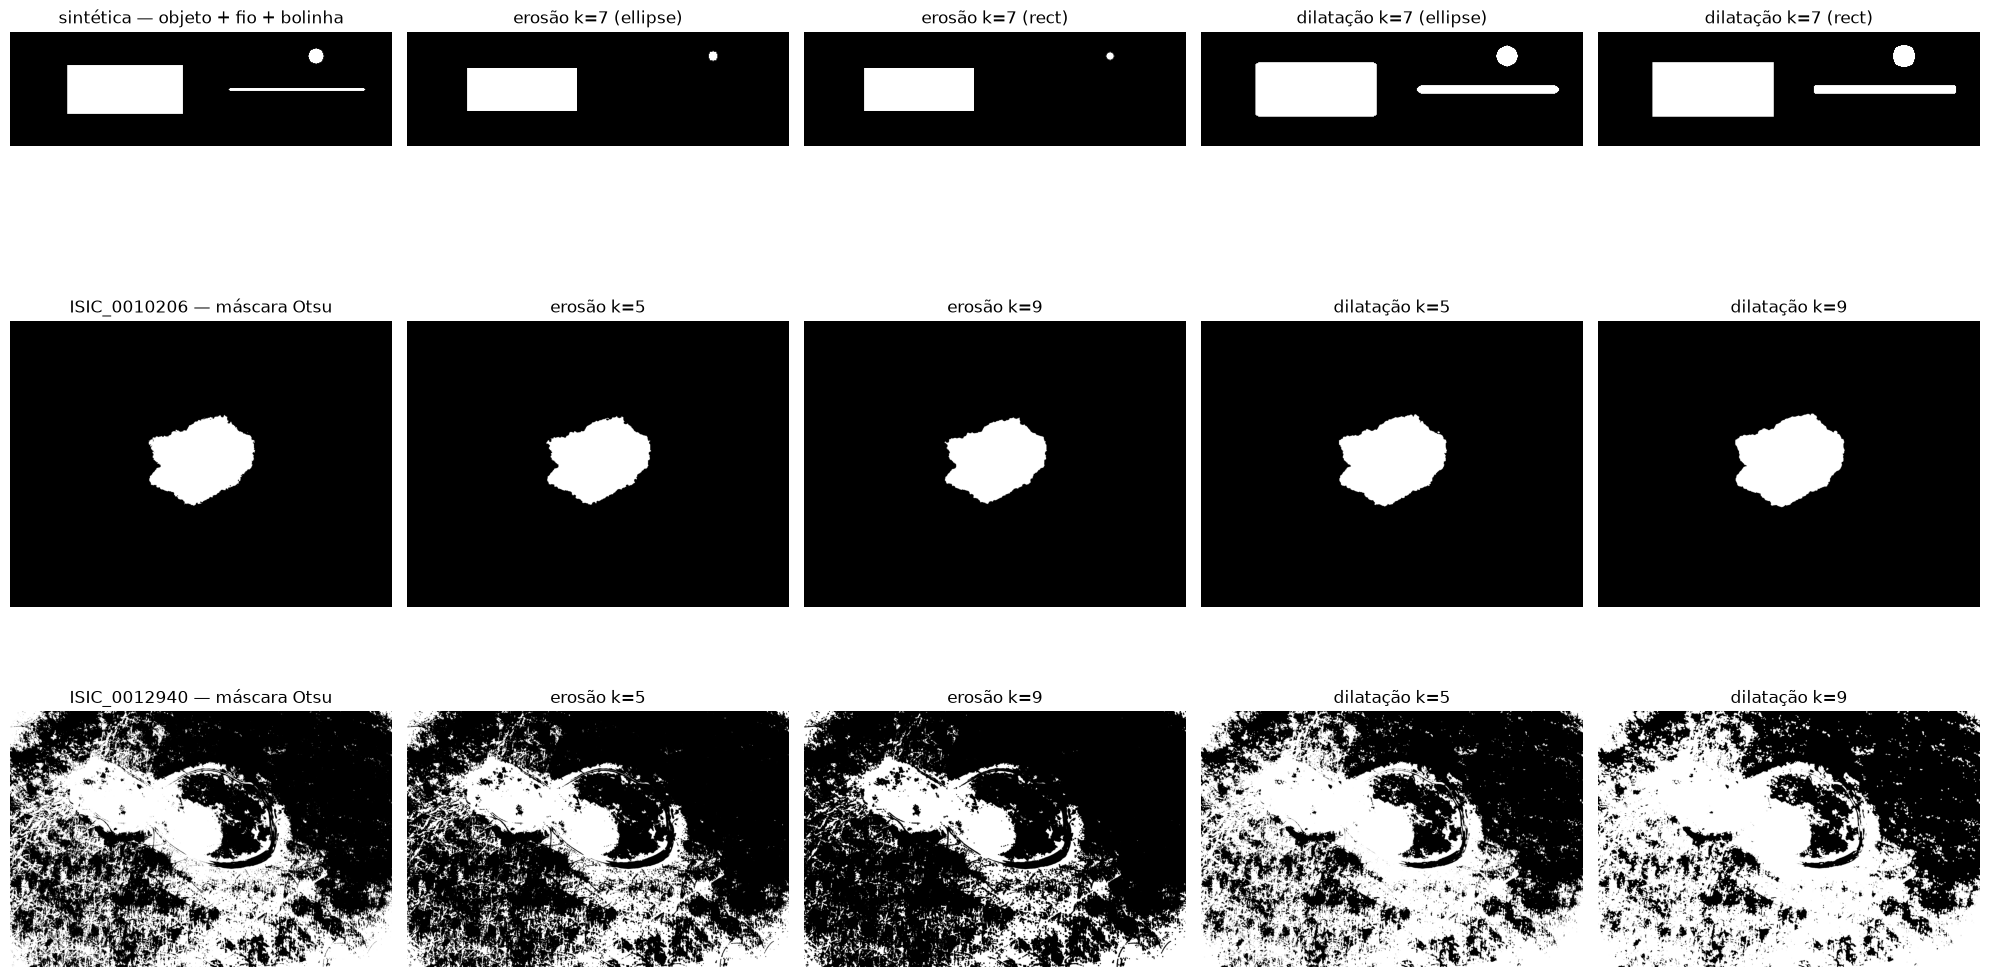

In [3]:
# linha 1: demo sintética (objeto grosso + fio de 2px + bolinha) — o conceito puro
sintetica = np.zeros((120, 400), dtype=np.uint8)
cv2.rectangle(sintetica, (60, 35), (180, 85), 255, -1)   # objeto grosso
cv2.line(sintetica, (230, 60), (370, 60), 255, 2)        # fio fino = "pelo"
cv2.circle(sintetica, (320, 25), 8, 255, -1)             # bolinha = "ruído"

# linhas 2-3: as máscaras reais do Passo 14
fig, axes = plt.subplots(3, 5, figsize=(20, 12))

painel_sintetico = [
    (sintetica, "sintética — objeto + fio + bolinha"),
    (erosao(sintetica, 7), "erosão k=7 (ellipse)"),
    (erosao(sintetica, 7, "rect"), "erosão k=7 (rect)"),
    (dilatacao(sintetica, 7), "dilatação k=7 (ellipse)"),
    (dilatacao(sintetica, 7, "rect"), "dilatação k=7 (rect)"),
]
for j, (img, tit) in enumerate(painel_sintetico):
    axes[0, j].imshow(img, cmap="gray")
    axes[0, j].set_title(tit)
    axes[0, j].axis("off")

for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"], start=1):
    cinza = para_cinza(carregar_imagem(PASTA_IMAGENS / nome))
    msk = segmentar_otsu(cinza)
    nome_curto = Path(nome).stem
    painel = [
        (msk, f"{nome_curto} — máscara Otsu"),
        (erosao(msk, 5), "erosão k=5"),
        (erosao(msk, 9), "erosão k=9"),
        (dilatacao(msk, 5), "dilatação k=5"),
        (dilatacao(msk, 9), "dilatação k=9"),
    ]
    for j, (img, tit) in enumerate(painel):
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].set_title(tit)
        axes[i, j].axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "morfologia" / "erosao_dilatacao.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)